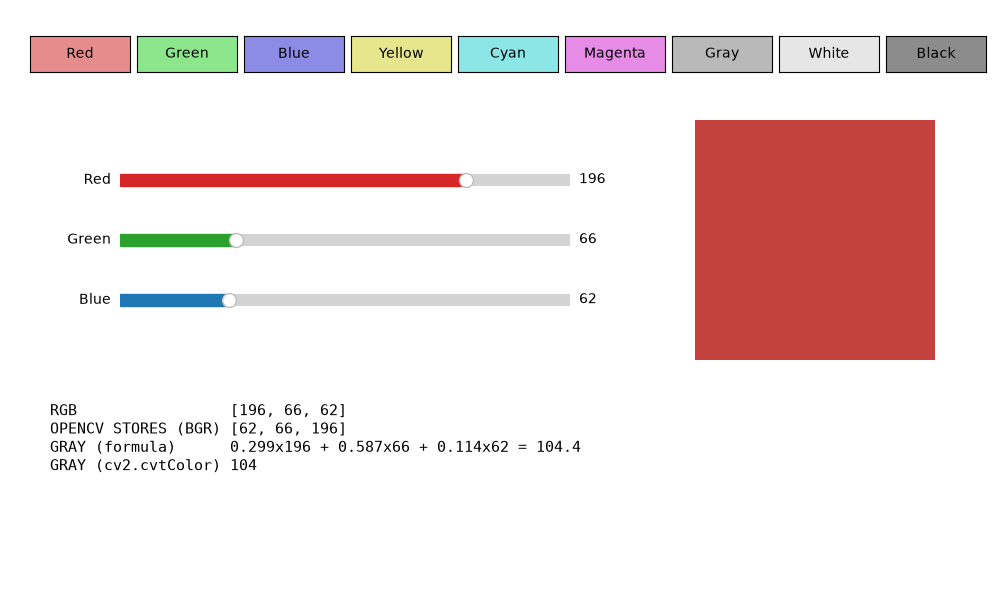

In [45]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button

PRESETS = {
    "Red": (255, 0, 0),     "Green": (0, 255, 0),   "Blue": (0, 0, 255)
}

def rgb_explorer(r=196, g=66, b=62):
    fig = plt.figure(figsize=(10, 6))

    # swatch
    ax_sw = fig.add_axes([0.68, 0.40, 0.27, 0.40]); ax_sw.axis("off")
    sw = ax_sw.imshow(np.full((10, 10, 3), (r, g, b), dtype=np.uint8))

    # info text
    ax_txt = fig.add_axes([0.05, 0.05, 0.9, 0.28]); ax_txt.axis("off")
    txt = ax_txt.text(0, 1, "", va="top", family="monospace", fontsize=11)

    # sliders
    sr = Slider(fig.add_axes([0.12, 0.68, 0.45, 0.04]), "Red",   0, 255, valinit=r, valstep=1, color="tab:red")
    sg = Slider(fig.add_axes([0.12, 0.58, 0.45, 0.04]), "Green", 0, 255, valinit=g, valstep=1, color="tab:green")
    sb = Slider(fig.add_axes([0.12, 0.48, 0.45, 0.04]), "Blue",  0, 255, valinit=b, valstep=1, color="tab:blue")

    def update(_=None):
        R, G, B = int(sr.val), int(sg.val), int(sb.val)
        sw.set_data(np.full((10, 10, 3), (R, G, B), dtype=np.uint8))

        # OpenCV stores BGR; build a 1x1 image and let OpenCV compute gray
        px_bgr = np.array([[[B, G, R]]], dtype=np.uint8)
        gray_cv = int(cv2.cvtColor(px_bgr, cv2.COLOR_BGR2GRAY)[0, 0])
        gray_formula = 0.299 * R + 0.587 * G + 0.114 * B

        txt.set_text(
            f"RGB                 [{R}, {G}, {B}]\n"
            f"OPENCV STORES (BGR) [{B}, {G}, {R}]\n"
            f"GRAY (formula)      0.299x{R} + 0.587x{G} + 0.114x{B} = {gray_formula:.1f}\n"
            f"GRAY (cv2.cvtColor) {gray_cv}"
        )
        fig.canvas.draw_idle()

    for s in (sr, sg, sb):
        s.on_changed(update)

    # preset buttons
    buttons = []
    for i, (name, (pr, pg, pb)) in enumerate(PRESETS.items()):
        bax = fig.add_axes([0.03 + i * 0.107, 0.88, 0.10, 0.06])
        btn = Button(bax, name, color=tuple(np.array([pr, pg, pb]) / 255 * 0.35 + 0.55))

        def on_click(_, pr=pr, pg=pg, pb=pb):
            sr.set_val(pr); sg.set_val(pg); sb.set_val(pb)

        btn.on_clicked(on_click)
        buttons.append(btn)

    update()
    plt.show()
    return sr, sg, sb, buttons   # keep widgets alive

widgets = rgb_explorer()